In [1]:
import copy
import logging

import numpy as np

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    Species,
    SpeciesCollection,
    bulk_silicate_earth_abundances,
    debug_logger,
    earth_oceans_to_hydrogen_mass,
)
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
logger.setLevel(logging.DEBUG)

Atmodeller initialized with double precision (float64)


# Trappist 1-e models from Bower et al. (2025)

Parameters for the simulations

In [2]:
# In the paper we perform 10,000 simulations
# number_of_realisations = 10000
number_of_realisations = 100
magma_ocean_temperature = 3000 #2500K-3000K
# In the paper we perform simulations at 0.1 and 1.0 melt fraction
mantle_melt_fraction = 1.0

# 
hot_surface_temperature = 740

# Corresponds to the highest temperature at which all condensates can form
medium_surface_temperature = 380

# Corresponds to the equilibrium temperature of Trappist-1e
cold_surface_temperature = 280

# For no particular reason, use 24 as the random seed
RANDOM_SEED = 24
WRITE_OUTPUT = True

# These are just to know at which temperatures condensates are stable
# Temperature must be equal to or less than these values for water condensation and water
# freezing to be applicable.
# water_condensation = 600.0  # First thermo data for H2O(l)

# For naming output data
magma_ocean_temp_str: str = f"{magma_ocean_temperature:0.0f}"
hot_temp_str: str = f"{hot_surface_temperature:0.0f}"
medium_temp_str: str = f"{medium_surface_temperature:0.0f}"
cold_temp_str: str = f"{cold_surface_temperature:0.0f}"

## High temperature atmospheric diversity (gas + C_cr)

Parameter space to probe. Generate once to ensure the same values are used across the high temperature models allowing direct comparison.

In [3]:
np.random.seed(RANDOM_SEED)
log10_number_oceans = np.random.uniform(-1, 1, number_of_realisations)
log10_ch_ratios = np.random.uniform(-1, 1, number_of_realisations)
fO2_log10_shifts = np.random.uniform(-5, 5, number_of_realisations)

h_kg = earth_oceans_to_hydrogen_mass(10**log10_number_oceans)
c_kg = h_kg * 10**log10_ch_ratios

trappist1e_mantle_mass = 2.912e24
trappist1e_planet_mass = trappist1e_mantle_mass / (1 - 0.295334691460966)
trappist1e_surface_radius = 5.861e6

fugacity_constraints = {"O2_g": IronWustiteBuffer(fO2_log10_shifts)}

Species that we need

In [4]:
H2O_g = Species.create_gas("H2O")
H2_g = Species.create_gas("H2")
O2_g = Species.create_gas("O2")
CO_g = Species.create_gas("CO")
CO2_g = Species.create_gas("CO2")
CH4_g = Species.create_gas("CH4")
N2_g = Species.create_gas("N2")
H3N_g = Species.create_gas("H3N")
# Graphite can also be present in high temperature atmospheres
C_cr = Species.create_condensed("C")
# Condensates below are used for cooler atmospheres
H2O_l = Species.create_condensed("H2O", state="l")


Species to consider, where solubility is not included

In [5]:
species_nosol = SpeciesCollection(
    (
        H2_g,
        H2O_g,
        O2_g,
        CO_g,
        CO2_g,
        CH4_g,
        N2_g,
        H3N_g,
        C_cr,
    )
)

TRAPPIST-1e planet properties

Mass and radius measurements from Agol et al. 2021; Mantle mass determined assuming same proportion as Earth

In [6]:
trappist1e_magma_ocean = Planet(
    surface_temperature=magma_ocean_temperature,
    planet_mass=trappist1e_planet_mass,
    surface_radius=trappist1e_surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

Earth planet properties, which are required to scale the bulk volatile inventories for Trappist-1e. Default parameters are Earth so we only need to specify the temperature.

In [7]:
earth = Planet(surface_temperature=magma_ocean_temperature)

In [8]:
earth_bse = bulk_silicate_earth_abundances()

Compute the reservoir sizes for TRAPPIST 1-e, assuming the same ppmw as Earth:

In [9]:
trappist1e_bse = copy.deepcopy(earth_bse)
mass_scale_factor = trappist1e_magma_ocean.mantle_mass / earth.mantle_mass

for element, values in trappist1e_bse.items():
    trappist1e_bse[element] = {key: value * mass_scale_factor for key, value in values.items()}  # type: ignore

trappist1e_bse

{'H': {'min': Array(1.281532612814915e+20, dtype=float64),
  'max': Array(1.310595447446787e+21, dtype=float64),
  'mean': Array(7.19374354364139e+20, dtype=float64)},
 'C': {'min': Array(1.222714971298032e+20, dtype=float64),
  'max': Array(2.125738761645474e+21, dtype=float64),
  'mean': Array(1.124005129387639e+21, dtype=float64)},
 'S': {'min': Array(5.823638482424581e+20, dtype=float64),
  'max': Array(7.279548103030726e+20, dtype=float64),
  'mean': Array(6.551593292727653e+20, dtype=float64)},
 'N': {'min': Array(2.417059080217331e+18, dtype=float64),
  'max': Array(7.279548103030726e+18, dtype=float64),
  'mean': Array(4.848303591624028e+18, dtype=float64)},
 'Cl': {'min': Array(5.240997845280866e+19, dtype=float64),
  'max': Array(9.902122942430578e+19, dtype=float64),
  'mean': Array(7.571560393855723e+19, dtype=float64)}}

In [10]:
interior_atmosphere_nosol = InteriorAtmosphere(species_nosol)

mass_constraints = {
    "H": h_kg,
    "C": c_kg,
    "N": trappist1e_bse["N"]["mean"],
}

interior_atmosphere_nosol.solve(
    planet=trappist1e_magma_ocean,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
)
output_nosol = interior_atmosphere_nosol.output

# Quick look at the solution
# solution_nosol = output_nosol.quick_look()

# Get complete solution as a dictionary
# solution_nosol asdict = output_nosol.asdict()
# logger.info(solution_nosol_asdict)

if WRITE_OUTPUT:
    # Write the complete solution to Excel
    output_nosol.to_excel(f"t1e_{magma_ocean_temp_str}K_no_solubility")

    # Write the data to a pickle file with dataframes
    output_nosol.to_pickle(f"t1e_{magma_ocean_temp_str}K_no_solubility")

[17:02:42 - atmodeller.classes             - INFO     ] - species = ('H2_g: IdealGas, NoSolubility', 'H2O_g: IdealGas, NoSolubility', 'O2_g: IdealGas, NoSolubility', 'CO_g: IdealGas, NoSolubility', 'CO2_g: IdealGas, NoSolubility', 'CH4_g: IdealGas, NoSolubility', 'N2_g: IdealGas, NoSolubility', 'H3N_g: IdealGas, NoSolubility', 'C_cr: CondensateActivity, NoSolubility')
[17:02:42 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[17:02:42 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2O_g + 1.0 CO_g = 1.0 H2_g + 1.0 CO2_g',
 1: '3.0 H2_g + 1.0 CO_g = 1.0 H2O_g + 1.0 CH4_g',
 2: '2.0 H2O_g = 2.0 H2_g + 1.0 O2_g',
 3: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 4: '1.0 H2_g + 1.0 CO_g = 1.0 H2O_g + 1.0 C_cr'}
[17:02:42 - atmodeller.classes             - INFO     ] - Attempting to solve 100 model(s)
[17:02:43 - atmodeller.classes             - INFO     ] - Solve complete: 100 (100.00%) successful model(s)
[17:02

Cases with solubility

In [11]:
solubility_models = get_solubility_models()

In [12]:
H2O_g = Species.create_gas("H2O", solubility=solubility_models["H2O_basalt_dixon95"])
H2_g = Species.create_gas("H2", solubility=solubility_models["H2_basalt_hirschmann12"])
O2_g = Species.create_gas("O2")
CO_g = Species.create_gas("CO", solubility=solubility_models["CO_basalt_yoshioka19"])
CO2_g = Species.create_gas("CO2", solubility=solubility_models["CO2_basalt_dixon95"])
CH4_g = Species.create_gas("CH4", solubility=solubility_models["CH4_basalt_ardia13"])
N2_g = Species.create_gas("N2", solubility=solubility_models["N2_basalt_libourel03"])
H3N_g = Species.create_gas("H3N")
C_cr = Species.create_condensed("C")

species_withsol = SpeciesCollection(
    (
        H2_g,
        H2O_g,
        O2_g,
        CO_g,
        CO2_g,
        CH4_g,
        N2_g,
        H3N_g,
        C_cr,
    )
)

In [24]:
interior_atmosphere_withsol = InteriorAtmosphere(species_withsol)

mass_constraints = {
    "H": h_kg,
    "C": c_kg,
    "N": trappist1e_bse["N"]["mean"],
}

interior_atmosphere_withsol.solve(
    planet=trappist1e_magma_ocean,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
)
output_withsol = interior_atmosphere_withsol.output

# Quick look at the solution
# solution = output_withsol.quick_look()

# Get complete solution as a dictionary
# solution_withsol_asdict = output_withsol.asdict()
# logger.info(solution_withsol_asdict)

if WRITE_OUTPUT:
    # Write the complete solution to Excel
    output_withsol.to_excel(f"t1e_{magma_ocean_temp_str}K_with_solubility")

    # Write the data to a pickle file with dataframes
    output_withsol.to_pickle(f"t1e_{magma_ocean_temp_str}K_with_solubility")

[17:08:51 - atmodeller.classes             - INFO     ] - species = ('H2_g: IdealGas, SolubilityPowerLawLog10', 'H2O_g: IdealGas, SolubilityPowerLaw', 'O2_g: IdealGas, NoSolubility', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CH4_g: IdealGas, _CH4_basalt_ardia13', 'N2_g: IdealGas, _N2_basalt_libourel03', 'H3N_g: IdealGas, NoSolubility', 'C_cr: CondensateActivity, NoSolubility')
[17:08:51 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[17:08:51 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2O_g + 1.0 CO_g = 1.0 H2_g + 1.0 CO2_g',
 1: '3.0 H2_g + 1.0 CO_g = 1.0 H2O_g + 1.0 CH4_g',
 2: '2.0 H2O_g = 2.0 H2_g + 1.0 O2_g',
 3: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 4: '1.0 H2_g + 1.0 CO_g = 1.0 H2O_g + 1.0 C_cr'}
[17:08:51 - atmodeller.classes             - INFO     ] - Attempting to solve 100 model(s)
[17:08:51 - atmodeller.classes             - INFO     ] - Solve c

# Solidified planet

Get the starting abundances for the calculations:

In [14]:
withsol_dict = output_withsol.asdict()

# Create a dictionary with the series
mass_constraints = {
    "H": withsol_dict["element_H"]["atmosphere_mass"],
    "N": withsol_dict["element_N"]["atmosphere_mass"],
    "O": withsol_dict["element_O"]["atmosphere_mass"],
    # For C, we need to add the condensed mass to the atmosphere mass since the assumption is that
    # they remain in equilibrium
    "C": withsol_dict["element_C"]["atmosphere_mass"]
    + withsol_dict["element_C"]["condensed_mass"],
}

[17:02:48 - atmodeller.output_core         - INFO     ] - Returning cached asdict output


# Hot Venus-like surface temperature

In [15]:
interior_atmosphere_hot = InteriorAtmosphere(species_nosol)

trappist1e_hot = Planet(
    surface_temperature=hot_surface_temperature,
    planet_mass=trappist1e_planet_mass,
    surface_radius=trappist1e_surface_radius,
    mantle_melt_fraction=0.0,  # Always zero because the planet is solidified
)

interior_atmosphere_hot.solve(
    planet=trappist1e_hot,
    mass_constraints=mass_constraints,
    initial_log_number_density=interior_atmosphere_withsol.output.log_number_density,
    initial_log_stability=interior_atmosphere_withsol.output.log_stability,
)
output_hot = interior_atmosphere_hot.output

if WRITE_OUTPUT:
    # Write the complete solution to Excel
    output_hot.to_excel(f"t1e_{hot_temp_str}K")

    # Write the data to a pickle file with dataframes
    output_hot.to_pickle(f"t1e_{hot_temp_str}K")

[17:02:48 - atmodeller.classes             - INFO     ] - species = ('H2_g: IdealGas, NoSolubility', 'H2O_g: IdealGas, NoSolubility', 'O2_g: IdealGas, NoSolubility', 'CO_g: IdealGas, NoSolubility', 'CO2_g: IdealGas, NoSolubility', 'CH4_g: IdealGas, NoSolubility', 'N2_g: IdealGas, NoSolubility', 'H3N_g: IdealGas, NoSolubility', 'C_cr: CondensateActivity, NoSolubility')
[17:02:48 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[17:02:48 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2O_g + 1.0 CO_g = 1.0 H2_g + 1.0 CO2_g',
 1: '3.0 H2_g + 1.0 CO_g = 1.0 H2O_g + 1.0 CH4_g',
 2: '2.0 H2O_g = 2.0 H2_g + 1.0 O2_g',
 3: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 4: '1.0 H2_g + 1.0 CO_g = 1.0 H2O_g + 1.0 C_cr'}
[17:02:48 - atmodeller.classes             - INFO     ] - Attempting to solve 100 model(s)
[17:02:49 - atmodeller.classes             - INFO     ] - Solve complete: 100 (100.00%) successful model(s)
[17:02

# Medium surface temperature where all condensates can be stable

In [16]:
species_with_all_condensates = SpeciesCollection(
    (
        H2_g,
        H2O_g,
        O2_g,
        CO_g,
        CO2_g,
        CH4_g,
        N2_g,
        H3N_g,
        C_cr,
        H2O_l,
    )
)

In [21]:
interior_atmosphere_medium = InteriorAtmosphere(species_with_all_condensates)

trappist1e_medium = Planet(
    surface_temperature=medium_surface_temperature,
    planet_mass=trappist1e_planet_mass,
    surface_radius=trappist1e_surface_radius,
    mantle_melt_fraction=0.1,  # Always zero because the planet is solidified
)

interior_atmosphere_medium.solve(
    planet=trappist1e_medium,
    mass_constraints=mass_constraints,
)
output_medium = interior_atmosphere_medium.output

if WRITE_OUTPUT:
    # Write the complete solution to Excel
    output_medium.to_excel(f"t1e_{medium_temp_str}K")

    # Write the data to a pickle file with dataframes
    output_medium.to_pickle(f"t1e_{medium_temp_str}K")

[17:06:11 - atmodeller.classes             - INFO     ] - species = ('H2_g: IdealGas, SolubilityPowerLawLog10', 'H2O_g: IdealGas, SolubilityPowerLaw', 'O2_g: IdealGas, NoSolubility', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CH4_g: IdealGas, _CH4_basalt_ardia13', 'N2_g: IdealGas, _N2_basalt_libourel03', 'H3N_g: IdealGas, NoSolubility', 'C_cr: CondensateActivity, NoSolubility', 'H2O_l: CondensateActivity, NoSolubility')
[17:06:11 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 274 K and 600 K
[17:06:11 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2O_g + 1.0 CO_g = 1.0 H2_g + 1.0 CO2_g',
 1: '3.0 H2_g + 1.0 CO_g = 1.0 H2O_g + 1.0 CH4_g',
 2: '2.0 H2O_g = 2.0 H2_g + 1.0 O2_g',
 3: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 4: '1.0 H2_g + 1.0 CO_g = 1.0 H2O_g + 1.0 C_cr',
 5: '1.0 H2O_g = 1.0 H2O_l'}
[17:06:11 - atmodeller.classes             - INFO     ] - Attempting to solve 100 mod

# Cold surface temperature where all condensates can be stable

In [18]:
interior_atmosphere_cold = InteriorAtmosphere(species_with_all_condensates)

trappist1e_cold = Planet(
    surface_temperature=cold_surface_temperature,
    planet_mass=trappist1e_planet_mass,
    surface_radius=trappist1e_surface_radius,
    mantle_melt_fraction=0.0,  # Always zero because the planet is solidified
)

interior_atmosphere_cold.solve(
    planet=trappist1e_cold,
    mass_constraints=mass_constraints,
    initial_log_number_density=interior_atmosphere_medium.output.log_number_density,
    initial_log_stability=interior_atmosphere_medium.output.log_stability,
)
output_cold = interior_atmosphere_cold.output

if WRITE_OUTPUT:
    # Write the complete solution to Excel
    output_cold.to_excel(f"t1e_{cold_temp_str}K")

    # Write the data to a pickle file with dataframes
    output_cold.to_pickle(f"t1e_{cold_temp_str}K")

[17:02:53 - atmodeller.classes             - INFO     ] - species = ('H2_g: IdealGas, SolubilityPowerLawLog10', 'H2O_g: IdealGas, SolubilityPowerLaw', 'O2_g: IdealGas, NoSolubility', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CH4_g: IdealGas, _CH4_basalt_ardia13', 'N2_g: IdealGas, _N2_basalt_libourel03', 'H3N_g: IdealGas, NoSolubility', 'C_cr: CondensateActivity, NoSolubility', 'H2O_l: CondensateActivity, NoSolubility')
[17:02:53 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 274 K and 600 K
[17:02:53 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2O_g + 1.0 CO_g = 1.0 H2_g + 1.0 CO2_g',
 1: '3.0 H2_g + 1.0 CO_g = 1.0 H2O_g + 1.0 CH4_g',
 2: '2.0 H2O_g = 2.0 H2_g + 1.0 O2_g',
 3: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 4: '1.0 H2_g + 1.0 CO_g = 1.0 H2O_g + 1.0 C_cr',
 5: '1.0 H2O_g = 1.0 H2O_l'}
[17:02:53 - atmodeller.classes             - INFO     ] - Attempting to solve 100 mod

Varying planet mass

In [32]:
interior_atmosphere_hot = InteriorAtmosphere(species_with_all_condensates)

trappist1e_hot = Planet(
    surface_temperature=hot_surface_temperature,
    planet_mass=trappist1e_planet_mass,
    surface_radius=trappist1e_surface_radius,
    mantle_melt_fraction=0.1,
)

interior_atmosphere_hot.solve(
    planet=trappist1e_hot,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints
)
output_hot = interior_atmosphere_hot.output

if WRITE_OUTPUT:
    # Write the complete solution to Excel
    output_hot.to_excel(f"t1e_{hot_temp_str}K")

    # Write the data to a pickle file with dataframes
    output_hot.to_pickle(f"t1e_{hot_temp_str}K")

[17:14:23 - atmodeller.classes             - INFO     ] - species = ('H2_g: IdealGas, SolubilityPowerLawLog10', 'H2O_g: IdealGas, SolubilityPowerLaw', 'O2_g: IdealGas, NoSolubility', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CH4_g: IdealGas, _CH4_basalt_ardia13', 'N2_g: IdealGas, _N2_basalt_libourel03', 'H3N_g: IdealGas, NoSolubility', 'C_cr: CondensateActivity, NoSolubility', 'H2O_l: CondensateActivity, NoSolubility')
[17:14:23 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 274 K and 600 K
[17:14:23 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2O_g + 1.0 CO_g = 1.0 H2_g + 1.0 CO2_g',
 1: '3.0 H2_g + 1.0 CO_g = 1.0 H2O_g + 1.0 CH4_g',
 2: '2.0 H2O_g = 2.0 H2_g + 1.0 O2_g',
 3: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 4: '1.0 H2_g + 1.0 CO_g = 1.0 H2O_g + 1.0 C_cr',
 5: '1.0 H2O_g = 1.0 H2O_l'}
[17:14:23 - atmodeller.classes             - INFO     ] - Attempting to solve 100 mod

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_molecular_budget_from_excels(excel_file, species=None):
    """
    Plot molecular budget (atmosphere vs dissolved vs condensed)
    for each species from a real-gas Excel output file.
    Automatically combines gas/liquid/solid sheets for the same molecule.
    """

    print("\n" + "="*70)
    print("Creating molecular budget plot from:", excel_file)
    print("="*70)
    
    # Default species to plot
    if species is None:
        species = ['H2O', 'H2', 'CH4', 'CO2', 'CO', 'O2']
    
    # --- 1) Read hydrogen fraction as x-axis
    df_H = pd.read_excel(excel_file, sheet_name='element_H')
    if 'atmosphere_ppmw' in df_H.columns:
        H_frac_percent = df_H['atmosphere_ppmw'].values / 1e4  # ppmw → %
    else:
        raise KeyError("The sheet 'element_H' must contain 'atmosphere_ppmw' for the H mass fraction axis.")
    
    # --- 2) Create figure
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    axes = axes.flatten()
    
    all_sheets = pd.ExcelFile(excel_file).sheet_names
    
    for i, sp in enumerate(species):
        ax = axes[i]
        print(f"\nProcessing {sp} ...")
        
        # possible sheet names for each phase
        candidate_sheets = [f"{sp}_g", f"{sp}_l", f"{sp}_cr"]
        dfs = []
        
        for sh in candidate_sheets:
            if sh in all_sheets:
                try:
                    dfs.append(pd.read_excel(excel_file, sheet_name=sh))
                except Exception:
                    print(f"⚠️ Could not read {sh}.")
                    continue
        
        if not dfs:
            print(f"⚠️ Skipping {sp}: no matching sheets found.")
            continue
        
        # combine all phases (align by index)
        df = pd.concat(dfs, axis=0, ignore_index=True)
        
        # Ensure required columns exist
        if not {'atmosphere_mass', 'dissolved_mass'}.issubset(df.columns):
            print(f"⚠️ Skipping {sp}: missing mass columns.")
            continue
        
        atm_mass = df['atmosphere_mass'].values
        dis_mass = df['dissolved_mass'].values
        con_mass = df['total_mass'].values if 'condensed_mass' in df.columns else np.zeros_like(atm_mass)
        
        # average or sum across same H fraction samples
        # assume same number of points as H_frac_percent
        n = len(H_frac_percent)
        if len(atm_mass) != n:
            # if different length, interpolate or trim
            atm_mass = np.interp(np.linspace(0, 1, n), np.linspace(0, 1, len(atm_mass)), atm_mass)
            dis_mass = np.interp(np.linspace(0, 1, n), np.linspace(0, 1, len(dis_mass)), dis_mass)
            con_mass = np.interp(np.linspace(0, 1, n), np.linspace(0, 1, len(con_mass)), con_mass)
        
        total_mass = atm_mass + dis_mass + con_mass
        total_mass[total_mass == 0] = np.nan  # avoid divide-by-zero
        
        # --- Stacked area plot in %
        ax.fill_between(H_frac_percent, 0, atm_mass/total_mass*100, 
                        label='Atmosphere', color='#1f77b4', alpha=0.7)
        ax.fill_between(H_frac_percent, atm_mass/total_mass*100, 
                        (atm_mass+dis_mass)/total_mass*100, 
                        label='Dissolved', color='#ff7f0e', alpha=0.7)
        if np.any(con_mass > 0):
            ax.fill_between(H_frac_percent, (atm_mass+dis_mass)/total_mass*100, 100, 
                            label='Condensed', color='#2ca02c', alpha=0.7)
        
        # --- Formatting
        ax.set_xscale('log')
        ax.set_xlim(H_frac_percent.min(), H_frac_percent.max())
        ax.set_ylim(0, 100)
        ax.set_xlabel("H Mass Fraction (%)")
        ax.set_ylabel("Distribution (%)")
        ax.set_title(f"({chr(97+i)}) {sp.upper()} Budget", fontweight='bold')
        ax.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)
        
        if i == 0:
            ax.legend(frameon=True, fontsize=9)
    
    # Hide any unused subplots
    for j in range(len(species), len(axes)):
        fig.delaxes(axes[j])
    
    plt.tight_layout()
    plt.savefig("sub_neptune_molecular_budget.png", dpi=300, bbox_inches='tight')
    print("\n✓ Successfully saved: sub_neptune_molecular_budget.png")
    print("="*70)
    plt.show()



Creating molecular budget plot from: t1e_740K.xlsx

Processing H2O ...

Processing H2 ...

Processing CH4 ...

Processing CO2 ...

Processing CO ...

Processing O2 ...

✓ Successfully saved: sub_neptune_molecular_budget.png


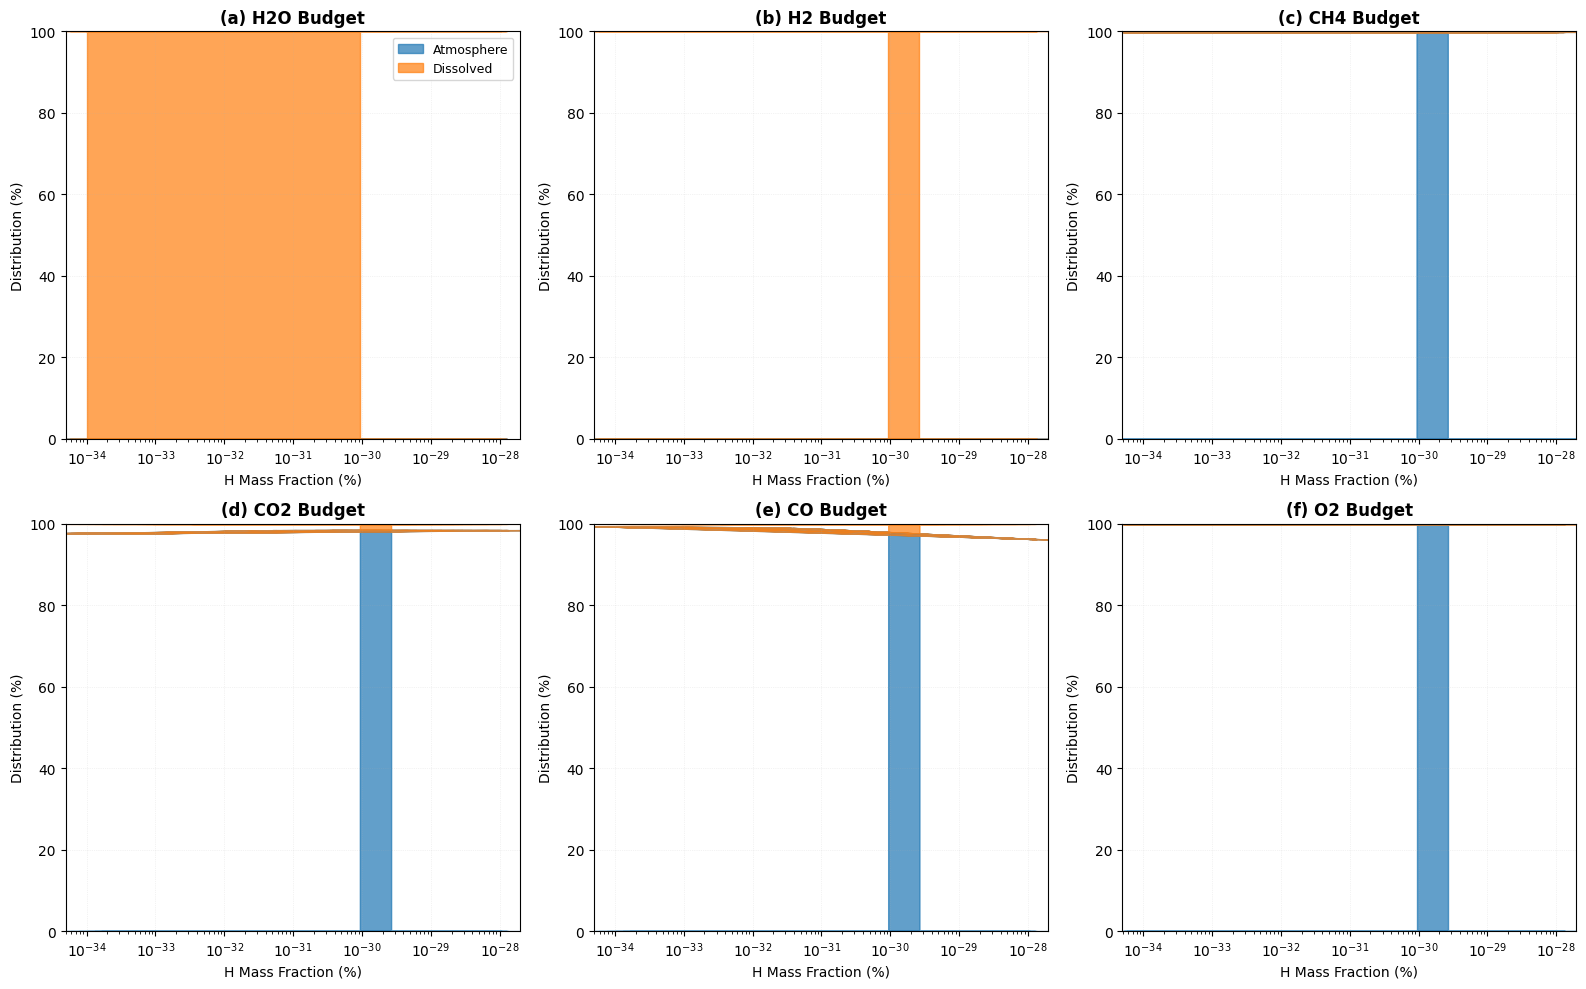

In [34]:
plot_molecular_budget_from_excels("t1e_740K.xlsx")
